In [121]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# (2.5 балла) Задача 1. Ошибки в диктанте

Пусть число ошибок в диктанте $X$ имеет следующее распределение.

| $x$ | $0$ | $1$ | $2$ | $3$ | $4$ | $5$ |
|---:|---:|---:|---:|---:|---:|---:|
| $\mathbb{P}(X=x)$ | $0.1$ | $0.2$ | $0.3$ | $0.2$ | $0.15$ | $0.05$ |

Оценка в 10-балльной шкале $Y$ вычисляется по формуле $Y=10-2X$.

1. Докажи, что $X$ и $Y$ могут выступать в качестве PMF случайных величин;
2. Визуализируй гистограммы распределений $X$ и $Y$;
3. Найди $\mathbb{E}(X)$ и $\mathbb{E}(Y)$;
4. Найди $\mathbb{E}(X^2)$ и $\mathbb{E}(Y^2)$;
5. Найди $\operatorname{Var}(X)$ и $\operatorname{Var}(Y)$;
6. Найди третий начальный момент, третий центральный момент и асимметрию для $X$, а с помощью неё - асимметрию для $Y$;
7. Найди четвёртый начальный момент, эксцесс и куртозис $X$, а также ээксцесс и куртозис $Y$;


<>:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
<>:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
/tmp/ipykernel_1742/3321662284.py:5: SyntaxWarning: assertion is always true, perhaps remove parentheses?
  assert(prob.sum(), 1)


Да, X и Y могут выступать в качестве PMF


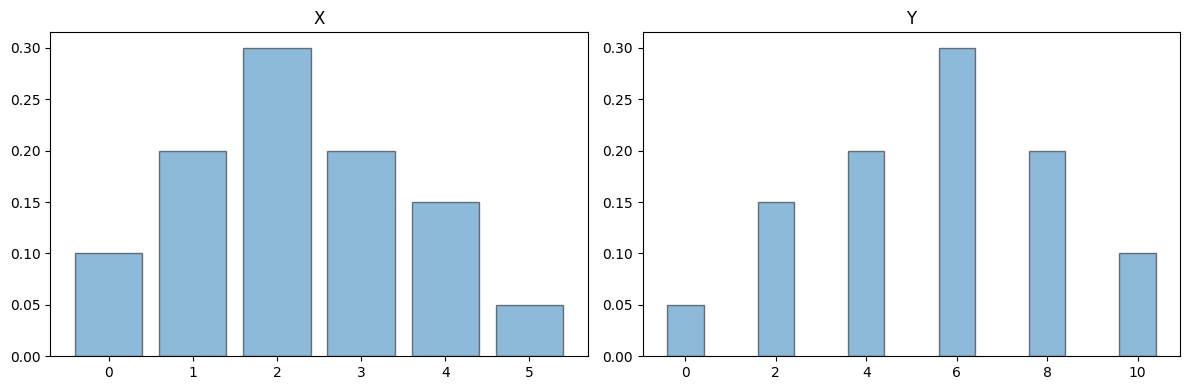

In [122]:
X = np.array([0, 1, 2, 3, 4, 5])
Y = 10 - 2 * X
prob = np.array([0.1, 0.2, 0.3, 0.2, 0.15, 0.05])

assert(prob.sum(), 1)

print("Да, X и Y могут выступать в качестве PMF")

fig, axes = plt.subplots(1, 2, figsize=(12, 4)) 

axes[0].bar(X, prob, alpha=.5, edgecolor="black")
axes[0].set_title("X")


axes[1].bar(Y, prob, alpha=.5, edgecolor="black")
axes[1].set_title("Y")

plt.tight_layout()
plt.show()


In [123]:
#Матожи

mu_X = np.sum(X * prob)
mu_Y = np.sum(Y * prob)

mu_X_square = np.sum(X * X * prob)
mu_Y_square = np.sum(Y * Y * prob)

var_X = mu_X_square - mu_X**2
var_Y = mu_Y_square - mu_Y**2


# 3ий начальный момент
mu_X_cube = np.sum(X**3 * prob)

# 3ий центральный момент
third_central_moment_X = np.sum((X - mu_X)**3 * prob)

skewness_X = third_central_moment_X /  var_X**(3/2)
skewness_Y = (-2)**3 / abs(-2)**3 * skewness_X


# 4ый центральный момент
fourth_central_moment_X = np.sum((X - mu_X)**4 * prob)
fourth_central_moment_Y = np.sum((Y - mu_Y)**4 * prob)

# Куртозис
kurtosis_X = fourth_central_moment_X / var_X**2
kurtosis_Y = fourth_central_moment_Y / var_Y**2

# Эксцесс
excess_kurtosis_X = kurtosis_X - 3
excess_kurtosis_Y = kurtosis_Y - 3


fourth_raw_moment_X = np.sum(X**4 * prob)

print("Математическое ожидание X:", mu_X)
print("Математическое ожидание Y:", mu_Y)

print("Второй начальный момент X:", mu_X_square)
print("Второй начальный момент Y:", mu_Y_square)

print("Дисперсия X:", var_X)
print("Дисперсия Y:", var_Y)

print("Третий начальный момент X:", mu_X_cube)
print("Третий центральный момент X:", third_central_moment_X)

print("Асимметрия X:", skewness_X)
print("Асимметрия Y:", skewness_Y)


print("Четвёртый начальный момент X:", fourth_raw_moment_X)

print("Четвёртый центральный момент X:", fourth_central_moment_X)
print("Четвёртый центральный момент Y:", fourth_central_moment_Y)

print("Куртозис X:", kurtosis_X)
print("Куртозис Y:", kurtosis_Y)

print("Эксцесс X:", excess_kurtosis_X)
print("Эксцесс Y:", excess_kurtosis_Y)

Математическое ожидание X: 2.25
Математическое ожидание Y: 5.5
Второй начальный момент X: 6.85
Второй начальный момент Y: 37.400000000000006
Дисперсия X: 1.7874999999999996
Дисперсия Y: 7.150000000000006
Третий начальный момент X: 23.85
Третий центральный момент X: 0.39374999999999993
Асимметрия X: 0.16475988914834352
Асимметрия Y: -0.16475988914834352
Четвёртый начальный момент X: 90.85
Четвёртый центральный момент X: 7.382031250000001
Четвёртый центральный момент Y: 118.11250000000001
Куртозис X: 2.310381925766542
Куртозис Y: 2.3103819257665377
Эксцесс X: -0.6896180742334579
Эксцесс Y: -0.6896180742334623


# (2 балла) Задача 2. Бросок кубика и ЦПТ

Пусть кубик бросается $900$ раз. Пусть $\xi$ — количество шестёрок.

Найти, используя приближение Муавра — Лапласа:

1. $\mathbb{P}(\xi=150)$ и $\mathbb{P}(\xi=130)$
2. $\mathbb{P}(130\leq \xi<170)$
3. $\mathbb{P}(\xi\geq 170)$. Сравни полученный в этом пункте результат с результатом неравенства Чебышева
4. Такое количество шестёрок при бросании кубика $900$ раз, что вероятность попадания в этот интервал $(150-x,150+x)$ составляет $95\%$.

In [124]:
from scipy.stats import norm

n = 900
p = 1/6

mu = n * p
sigma = np.sqrt(n * p * (1 - p))
approx = norm(loc=mu, scale=sigma)

p_150 = approx.pdf(150)
p_130 = approx.pdf(130)

print(f"P(ksi = 150) ≈ {p_150:.4f} ({p_150:.2%})")
print(f"P(ksi = 130) ≈ {p_130:.4f} ({p_130:.2%})")

p_interval = approx.cdf(170) - approx.cdf(130)

print(f"P(130 ≤ ksi < 170) ≈ {p_interval:.4f} ({p_interval:.2%})")

p_more_170 = approx.sf(170)
chebyshev_bound = sigma**2 / (170 - mu)**2

print(f"Муавр — Лаплас: P(ksi ≥ 170) ≈ {p_more_170:.4f}")
print(f"Чебышёв: P(ksi ≥ 170) ≤ {chebyshev_bound:.4f}")

#k - ? :  P(150-x < xi < 150+x)=0.95 => 0.5 = 2*P(x_i < 150 - x) = 0.05
#approx.cdf(150 - x) = 0.025

for x in range(1, 901):
    if approx.cdf(mu - x) <= 0.025:
        solution = x
        break

coverage = approx.cdf(mu + solution) - approx.cdf(mu - solution)

print(f"Ответ x = : {solution}")
print(f"Проверка: {coverage:.4f}")


P(ksi = 150) ≈ 0.0357 (3.57%)
P(ksi = 130) ≈ 0.0072 (0.72%)
P(130 ≤ ksi < 170) ≈ 0.9264 (92.64%)
Муавр — Лаплас: P(ksi ≥ 170) ≈ 0.0368
Чебышёв: P(ksi ≥ 170) ≤ 0.3125
Ответ x = : 22
Проверка: 0.9509


# (5.5 баллов) Задача 2. Симуляция предельных теорем для распределения Лапласа

Необходимо показать работу предельных теорем для распределения Лапласа.

Распределение Лапласа имеет следующую функцию плотности:

$$f(x) = \frac{1}{2 \sigma} \exp\left(-\frac{|x-\mu|}{\sigma}\right)$$

Также известно, что мат.ожидание и дисперсия распределения лапласа конечны (т.е. предпосылки теорем удовлетворены).

Для всех заданий в качестве параметров возьми $\mu=1$ и $\sigma=2$.

По аналогии с другими распределениями его можно импортировать из библиотеки *scipy.stats* как **laplace**.

In [125]:
from scipy.stats import laplace

mu = 1
sigma = 2

## (1 балл) Пункт 1. Функции плотности и распределения

 1. Создай объект распределения Лапласа с соответствующими параметрами;
 2. Визуализируй функцию плотности для распределения Лапласа;
 3. Визуализируй функцию распределения для распределения Лапласа;

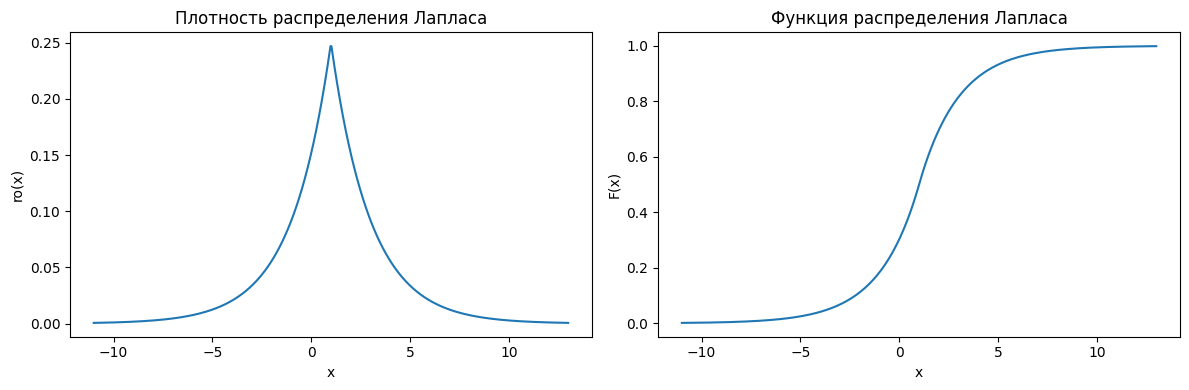

In [126]:
### Твой код здесь
rv = laplace(loc=mu, scale=sigma)

x = np.linspace(mu - 6*sigma, mu + 6*sigma, 500)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(x, rv.pdf(x))
axes[0].set_title("Плотность распределения Лапласа")
axes[0].set_xlabel("x")
axes[0].set_ylabel("ro(x)")

axes[1].plot(x, rv.cdf(x))
axes[1].set_title("Функция распределения Лапласа")
axes[1].set_xlabel("x")
axes[1].set_ylabel("F(x)")

plt.tight_layout()
plt.show()

## (1 балл) Пункт 2. Генерация выборки

 1. Создай выборку из данного распределения размером $300$ наблюдений;
 2. Рассчитай:
    - Выборочное среднее;
    - Первый квартиль выборки;
    - Третий квартиль выборки;
    - Первый дециль выборки;
    - Девятый дециль выборки;

 3. Визуализируй на гистограмме полученную выборку и на этом же графике вертикальными пунктирными линиями визуализируй рассчитанные выше выборочные показатели;


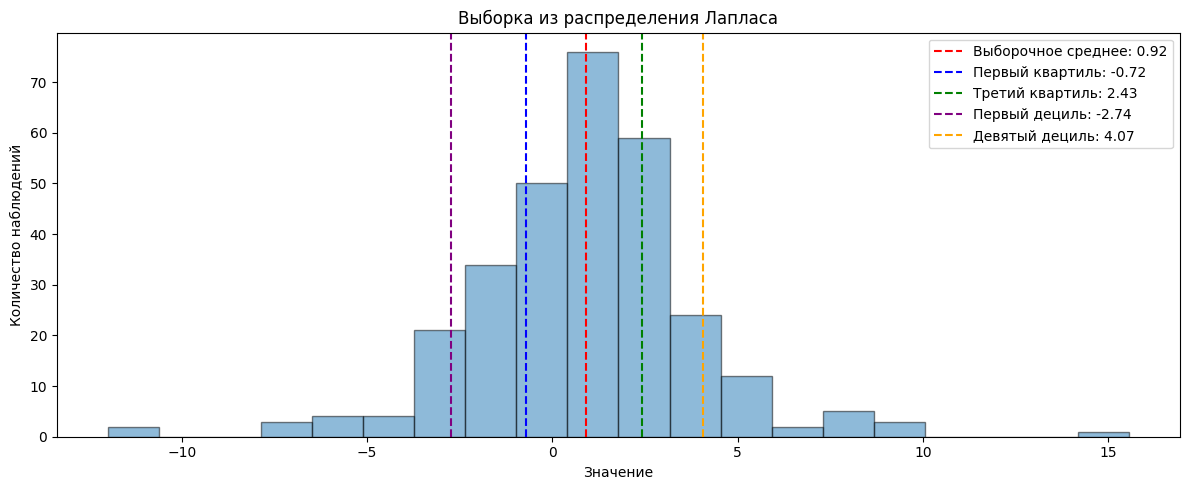

In [127]:
### Твой код здесь
sample = rv.rvs(size = 300)

mean = np.mean(sample)
q25, q75 = np.quantile(sample, [.25, .75])
q10, q90 = np.quantile(sample, [.1, .9])

fig, ax = plt.subplots(figsize=(12, 5))

ax.hist(sample, bins=20, alpha=0.5, edgecolor="black")

ax.axvline(mean, color="red", linestyle="--",
            label=f"Выборочное среднее: {mean:.2f}")
ax.axvline(q25, color="blue", linestyle="--",
            label=f"Первый квартиль: {q25:.2f}")
ax.axvline(q75, color="green", linestyle="--",
            label=f"Третий квартиль: {q75:.2f}")
ax.axvline(q10, color="purple", linestyle="--",
            label=f"Первый дециль: {q10:.2f}")
ax.axvline(q90, color="orange", linestyle="--",
            label=f"Девятый дециль: {q90:.2f}")

ax.set_title("Выборка из распределения Лапласа")
ax.set_xlabel("Значение")
ax.set_ylabel("Количество наблюдений")
ax.legend()

plt.tight_layout()
plt.show()



## (1.5 балла) Пункт 3. Закон Больших Чисел

 1. Создай двумерный вектор: $1000$ экспериментов по $1000$ значений распределения Лапласа;
 2. В каждом эксперименте рассчитай вектор кумулятивных средних;
 3. Визуализируй график, на котором видно, как выборочное среднее стремится к мат.ожиданию (для этого можно взять один из векторов с кумулятивным средним);
 4. Визуализируй вероятность выпадения среднего из эпсилон-коридора вокруг мат.ожидания. Продемонстрируй для значений эпсилон $0.1$ и $0.01$;

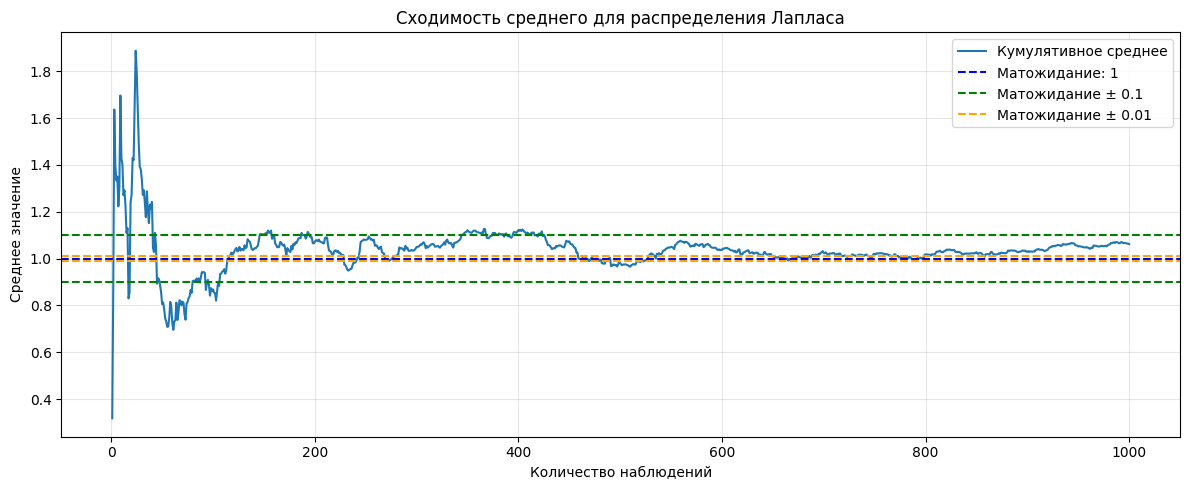

In [128]:
### Твой код здесь
matrix = rv.rvs(size=(1000, 1000))

sample_sizes = np.arange(1, matrix.shape[1] + 1)
x_mean = matrix.cumsum(axis=1) / sample_sizes

expected_value = rv.mean()
eps = .1
eps2 = .01

plt.figure(figsize=(12, 5))

plt.plot(sample_sizes, x_mean[0], label="Кумулятивное среднее")

plt.axhline(
    expected_value, color="blue", ls="--",
    label=f"Матожидание: {expected_value:g}"
)
plt.axhline(
    expected_value + eps, color="green", lw=1.5, ls="--",
    label=f"Матожидание ± {eps}"
)
plt.axhline(
    expected_value - eps, color="green", lw=1.5, ls="--"
)

plt.axhline(
    expected_value + eps2, color="orange", lw=1.5, ls="--",
    label=f"Матожидание ± {eps2}"
)
plt.axhline(
    expected_value - eps2, color="orange", lw=1.5, ls="--"
)

plt.title("Сходимость среднего для распределения Лапласа")
plt.xlabel("Количество наблюдений")
plt.ylabel("Среднее значение")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

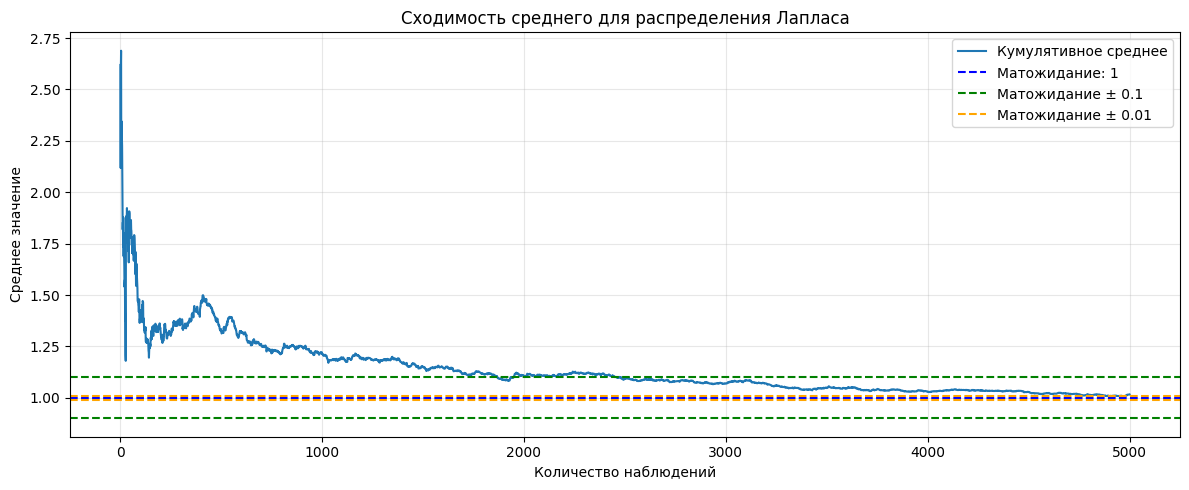

In [ ]:
# matrix = rv.rvs(size=(5000, 5000))
# sample_sizes = np.arange(1, matrix.shape[1] + 1)
# x_mean = matrix.cumsum(axis=1) / sample_sizes

# expected_value = rv.mean()
# eps = 0.1

# plt.figure(figsize=(12, 5))

# plt.plot(sample_sizes, x_mean[0], label="Кумулятивное среднее")

# plt.axhline(
#     expected_value, color="blue", ls="--",
#     label=f"Матожидание: {expected_value:g}"
# )
# plt.axhline(
#     expected_value + eps, color="green", lw=1.5, ls="--",
#     label=f"Матожидание ± {eps}"
# )
# plt.axhline(
#     expected_value - eps, color="green", lw=1.5, ls="--"
# )

# plt.axhline(
#     expected_value + eps2, color="orange", lw=1.5, ls="--",
#     label=f"Матожидание ± {eps2}"
# )
# plt.axhline(
#     expected_value - eps2, color="orange", lw=1.5, ls="--"
# )

# plt.title("Сходимость среднего для распределения Лапласа")
# plt.xlabel("Количество наблюдений")
# plt.ylabel("Среднее значение")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.tight_layout()
# plt.show()

In [130]:
bad_means1 = np.abs(x_mean - expected_value) > eps
bad_means2 = np.abs(x_mean - expected_value) > eps2

print(bad_means1[:3])
print(bad_means2[:3])

[[ True  True  True ... False False False]
 [ True  True  True ... False False False]
 [ True False  True ... False False False]]
[[ True  True  True ...  True  True  True]
 [ True  True  True ... False False  True]
 [ True False  True ...  True  True  True]]


In [131]:
prob1 = np.mean(bad_means1, axis=0)
prob2 = np.mean(bad_means2, axis=0)
print(prob1[:5])
print(prob2[:5])

[0.953 0.95  0.932 0.934 0.923]
[0.996 0.992 0.995 0.995 0.991]


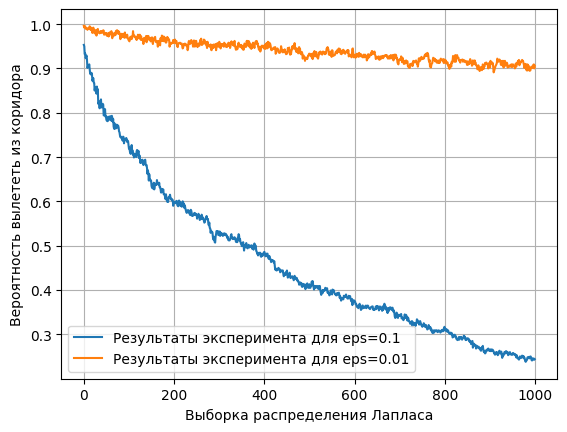

In [132]:
plt.plot(prob1, label = 'Результаты эксперимента для eps=0.1')
plt.plot(prob2, label = 'Результаты эксперимента для eps=0.01')
plt.xlabel('Выборка распределения Лапласа')
plt.ylabel('Вероятность вылететь из коридора')
plt.legend()
plt.grid()
plt.show()

## (1 балл) Пункт 4. Центральная Предельная Теорема

 1. Создай разное количество выборок по $1000$ наблюдений: $1$, $10$ и $10000$;
 2. Построй три графика с распределениями средних для каждого количества выборок, чтобы продемонстрировать стремление распределения среднего к нормальному;

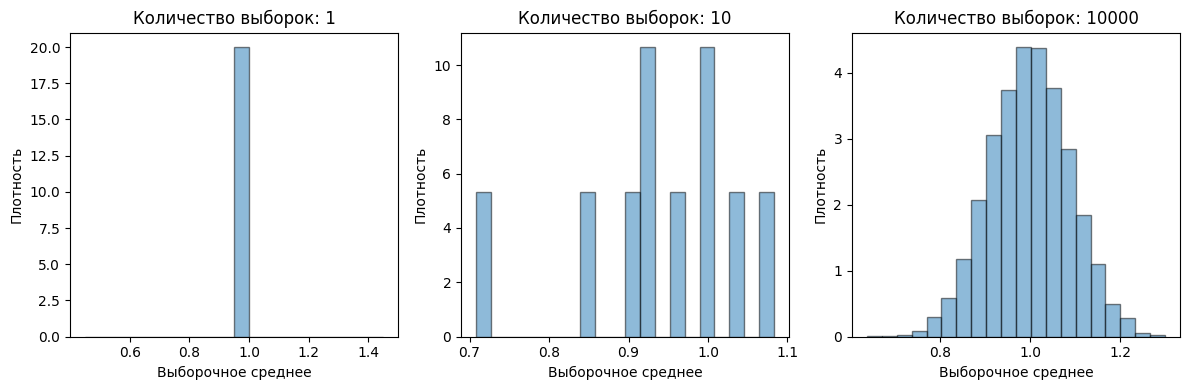

In [133]:
### Твой код здесь


fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for idx, i in enumerate([1, 10, 10000]):
    sample = rv.rvs(size=(i, 1000))
    sample_means = sample.mean(axis=1)

    axes[idx].hist(sample_means, bins=20, density=True,
                    alpha=0.5, edgecolor="black")
    axes[idx].set_title(f"Количество выборок: {i}")
    axes[idx].set_xlabel("Выборочное среднее")
    axes[idx].set_ylabel("Плотность")

plt.tight_layout()
plt.show()

## (1 балл) Пункт 5. Теорема Гливенко-Кантелли

 Ознакомься с теоремой Гливено-Кантелли о функции распределения.

 Затем продемонстрируй эту теорему с помощью симуляции на распределении Лапласа. Для этого:

 1. Создай набор точек для построения функции распределения, а также саму функцию распределения;
 2. Воспользуйся приведённой ниже функцией, чтобы рассчитать эмпирические CDF выборок размеров $10$, $100$ и $1000$;
 3. Визуализируй на отдельных графиках сравнение теоретической CDF и соответствующих выборочных CDF;
 4. Визуализируй ошибки как отклонения теоретической CDF от трёх различных эмпирических CDF на одном графике;

In [134]:
def empirical_cdf(data, x_points):
    n = len(data)
    ecdf_values = []

    for x in x_points:
        count = np.sum(data <= x)
        ecdf_values.append(count / n)

    return np.array(ecdf_values)

n = 10: максимальная ошибка на сетке = 0.1978
n = 100: максимальная ошибка на сетке = 0.0796
n = 1000: максимальная ошибка на сетке = 0.0297


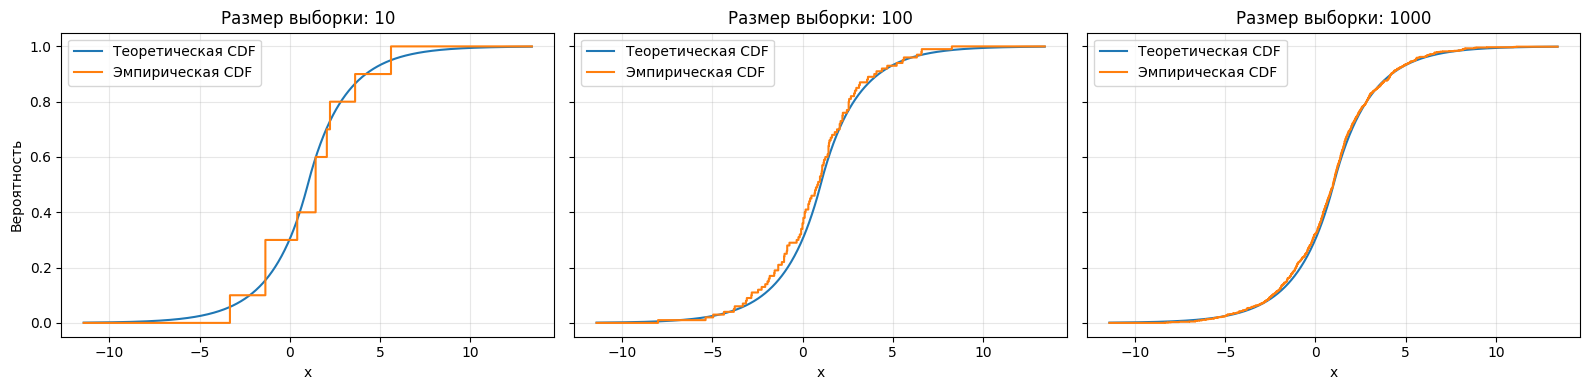

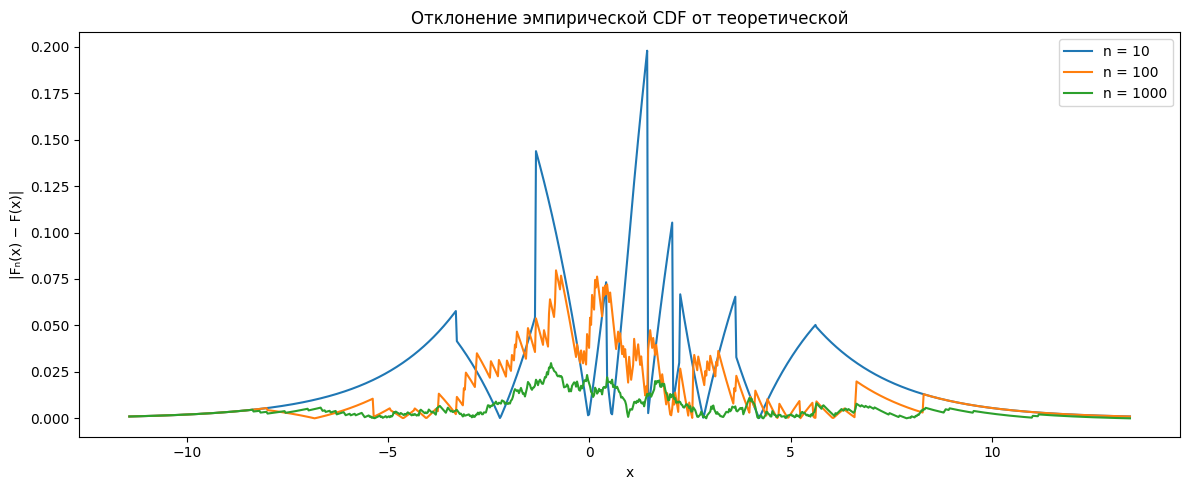

In [135]:
### Твой код здесь
sample = rv.rvs(size=1000, random_state=42)
sizes = [10, 100, 1000]

x = np.linspace(rv.ppf(0.001), rv.ppf(0.999), 1000)

empirical_cdfs = [
    empirical_cdf(sample[:n], x)
    for n in sizes
]

theoretical_cdf = rv.cdf(x)

fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)

for idx, n in enumerate(sizes):
    axes[idx].plot(x, theoretical_cdf, label="Теоретическая CDF")
    axes[idx].step(x, empirical_cdfs[idx],label="Эмпирическая CDF")
    axes[idx].set_title(f"Размер выборки: {n}")
    axes[idx].set_xlabel("x")
    axes[idx].legend()
    axes[idx].grid(alpha=0.3)

axes[0].set_ylabel("Вероятность")
plt.tight_layout()
plt.figure(figsize=(12, 5))

for n, sample_cdf in zip(sizes, empirical_cdfs):
    error = np.abs(sample_cdf - theoretical_cdf)
    plt.plot(x, error, label=f"n = {n}")
    print(f"n = {n}: максимальная ошибка на сетке = {error.max():.4f}")

plt.title("Отклонение эмпирической CDF от теоретической")
plt.xlabel("x")
plt.ylabel("|Fₙ(x) − F(x)|")
plt.legend()
plt.tight_layout()
plt.show()

# Бонусная задача

Если $X \sim \mathcal{N}(\mu, \sigma^2)$, то $Y = e^X$ имеет логнормальное распределение:
$$Y \sim Lognorm(\mu, \sigma^2)$$

Обратное преобразование:

$$X=\text{ln} Y \sim Norm(\mu, \sigma^2)$$

 1. Выведи функцию распределения и функцию плотности логнормального распределения и визуализируй функцию плотности для разных параметров.

 2. Выведи матожидание логнормального распределения.

 3. Выведи дисперсию логнормального распределения.

При $y>0$:
$$F_Y(y)=P(e^X\leq y)=P(X\leq\ln y)=\Phi\left(\frac{\ln y-\mu}{\sigma}\right)$$
Дифференцируя по $y$, получаем:
$$f_Y(y)=\varphi\left(\frac{\ln y-\mu}{\sigma}\right)\frac1{\sigma y}
=\frac1{y\sigma\sqrt{2\pi}}\exp\left(-\frac{(\ln y-\mu)^2}{2\sigma^2}\right)\qquad y>0$$
При $y\leq0$ плотность равна нулю.

--- 


$$\mathbb E[e^{tX}]=\frac1{\sigma\sqrt{2\pi}}\int_{-\infty}^{\infty}\exp\left(tx-\frac{(x-\mu)^2}{2\sigma^2}\right)\,dx$$

$$tx-\frac{(x-\mu)^2}{2\sigma^2}=-\frac{(x-\mu-t\sigma^2)^2}{2\sigma^2}+t\mu+\frac{t^2\sigma^2}{2}$$

$$\mathbb E[e^{tX}]=e^{t\mu+t^2\sigma^2/2}$$
При $t=1$:
$$\mathbb E[Y]=e^{\mu+\sigma^2/2}$$
При $t=2$:
$$\mathbb E[Y^2]=e^{2\mu+2\sigma^2}$$

---

$$\operatorname{Var}(Y)=\mathbb E[Y^2]-(\mathbb E[Y])^2=e^{2\mu+2\sigma^2}-e^{2\mu+\sigma^2}$$
$$\operatorname{Var}(Y)=e^{2\mu+\sigma^2}(e^{\sigma^2}-1)$$


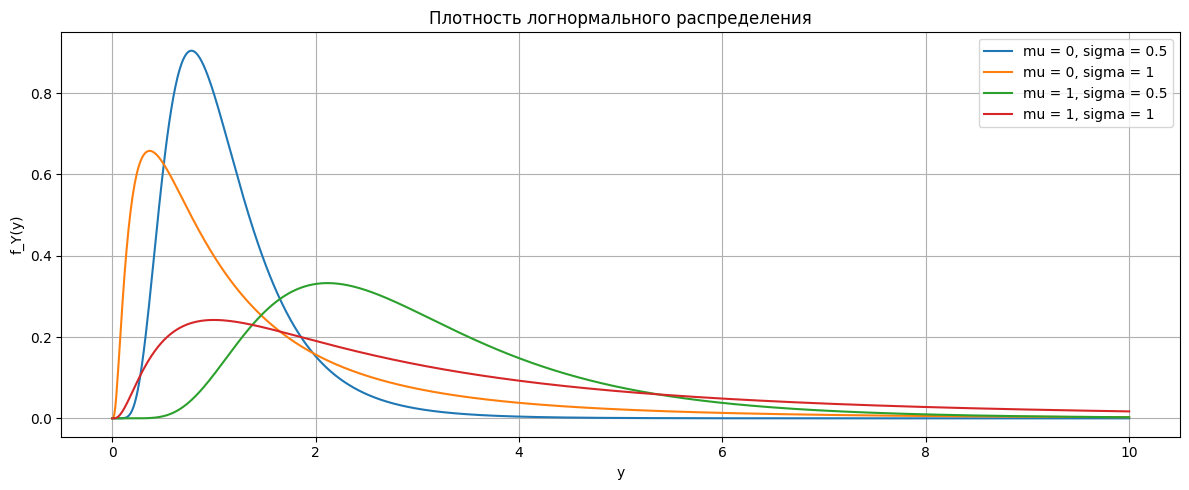

In [136]:
from scipy.stats import lognorm

y = np.linspace(0, 10, 1000)
parameters = [
      (0, 0.5),
      (0, 1),
      (1, 0.5),
      (1, 1),
  ]

plt.figure(figsize=(12, 5))

for mu_log, sigma_log in parameters:
    rv_log = lognorm(s=sigma_log, scale=np.exp(mu_log))
    plt.plot(y, rv_log.pdf(y),label=f"mu = {mu_log}, sigma = {sigma_log}")

plt.title("Плотность логнормального распределения")
plt.xlabel("y")
plt.ylabel("f_Y(y)")
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()